# Retail Demand Forecasting — Exploratory Data Analysis

This notebook explores historical retail demand across products, categories, stores, time periods, events, and pricing. The findings are used to guide feature engineering and forecasting model development.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load and Inspect the Data

The project uses the M5 retail forecasting dataset, which contains calendar, sales, and pricing information.

In [2]:
calendar = pd.read_csv("../data/raw/calendar.csv")
sales = pd.read_csv("../data/raw/sales_train_validation.csv")
prices = pd.read_csv("../data/raw/sell_prices.csv")

print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1919)
Prices: (6841121, 4)


### Dataset Structure and Data Quality

Inspect the datasets, their columns, data types, and missing values before beginning the analysis.

In [3]:
print(calendar.head())
print("\nColumns:")
print(calendar.columns.tolist())
print("\nMissing values:")
print(calendar.isna().sum())

         date  wm_yr_wk    weekday  wday  month  year    d event_name_1  \
0  2011-01-29     11101   Saturday     1      1  2011  d_1          NaN   
1  2011-01-30     11101     Sunday     2      1  2011  d_2          NaN   
2  2011-01-31     11101     Monday     3      1  2011  d_3          NaN   
3  2011-02-01     11101    Tuesday     4      2  2011  d_4          NaN   
4  2011-02-02     11101  Wednesday     5      2  2011  d_5          NaN   

  event_type_1 event_name_2 event_type_2  snap_CA  snap_TX  snap_WI  
0          NaN          NaN          NaN        0        0        0  
1          NaN          NaN          NaN        0        0        0  
2          NaN          NaN          NaN        0        0        0  
3          NaN          NaN          NaN        1        1        0  
4          NaN          NaN          NaN        1        0        1  

Columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_ty

In [4]:
print(sales.head())
print("\nColumns:")
print(sales.columns.tolist())
print("\nMissing values:")
print(sales.isna().sum())

                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1904  d_1905  d_1906  d_1907  d_1908  \
0       CA    0    0    0    0  ...       1       3       0       1       1   
1       CA    0    0    0    0  ...       0       0       0       0       0   
2       CA    0    0    0    0  ...       2       1       2       1       1   
3       CA    0    0    0    0  ...       1       0       5       4       1   
4       CA    0    0    0    0  ...       2       1       1       0       1   

   d_1909  d_1910  d_1911  d_1912  d_1913  


In [5]:
print(prices.head())
print("\nColumns:")
print(prices.columns.tolist())
print("\nMissing values:")
print(prices.isna().sum())

  store_id        item_id  wm_yr_wk  sell_price
0     CA_1  HOBBIES_1_001     11325        9.58
1     CA_1  HOBBIES_1_001     11326        9.58
2     CA_1  HOBBIES_1_001     11327        8.26
3     CA_1  HOBBIES_1_001     11328        8.26
4     CA_1  HOBBIES_1_001     11329        8.26

Columns:
['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

Missing values:
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64


### Identify Daily Sales Observations

The sales table stores daily demand in separate `d_` columns. These columns are identified for subsequent aggregation and analysis.

In [6]:
day_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]

print("Number of day columns:", len(day_columns))
print("First 5:", day_columns[:5])
print("Last 5:", day_columns[-5:])

Number of day columns: 1913
First 5: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5']
Last 5: ['d_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']


In [7]:
print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

print("\nSales identifier columns:")
print(
    sales.columns[
        ~sales.columns.isin(day_columns)
    ].tolist()
)

Calendar: (1969, 14)
Sales: (30490, 1919)
Prices: (6841121, 4)

Sales identifier columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']


In [8]:
print(sales.dtypes)

id            str
item_id       str
dept_id       str
cat_id        str
store_id      str
            ...  
d_1909      int64
d_1910      int64
d_1911      int64
d_1912      int64
d_1913      int64
Length: 1919, dtype: object


In [9]:
calendar["date"] = pd.to_datetime(calendar["date"])

print("Start:", calendar["date"].min())
print("End:", calendar["date"].max())

Start: 2011-01-29 00:00:00
End: 2016-06-19 00:00:00


In [12]:
print(
    prices.isna()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64


## 2. Overall Demand Analysis

Aggregate sales across all products and stores to examine overall demand levels, variability, and trends over time.

In [13]:
daily_sales = sales[day_columns].sum()

print(daily_sales.head())
print("\nNumber of days:", len(daily_sales))

d_1    32631
d_2    31749
d_3    23783
d_4    25412
d_5    19146
dtype: int64

Number of days: 1913


In [14]:
print(daily_sales.describe())

count     1913.000000
mean     34341.562467
std       7345.905196
min         11.000000
25%      29654.000000
50%      33732.000000
75%      38689.000000
max      57218.000000
dtype: float64


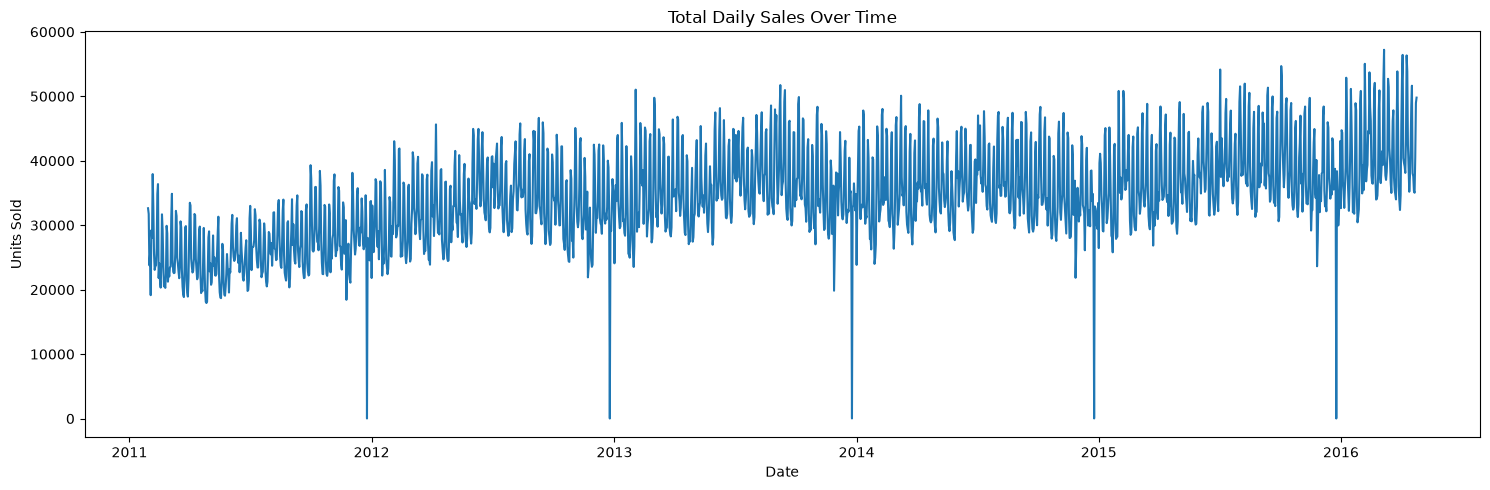

In [15]:
dates = calendar["date"].iloc[:len(daily_sales)]

daily_df = pd.DataFrame({
    "date": dates.values,
    "sales": daily_sales.values
})

plt.figure(figsize=(15, 5))

plt.plot(
    daily_df["date"],
    daily_df["sales"]
)

plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

## 3. Category Analysis

Compare total demand across product categories to identify differences in sales volume and category concentration.

In [16]:
category_sales = (
    sales.groupby("cat_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)

print(category_sales)

cat_id
FOODS        45089939
HOUSEHOLD    14480670
HOBBIES       6124800
dtype: int64


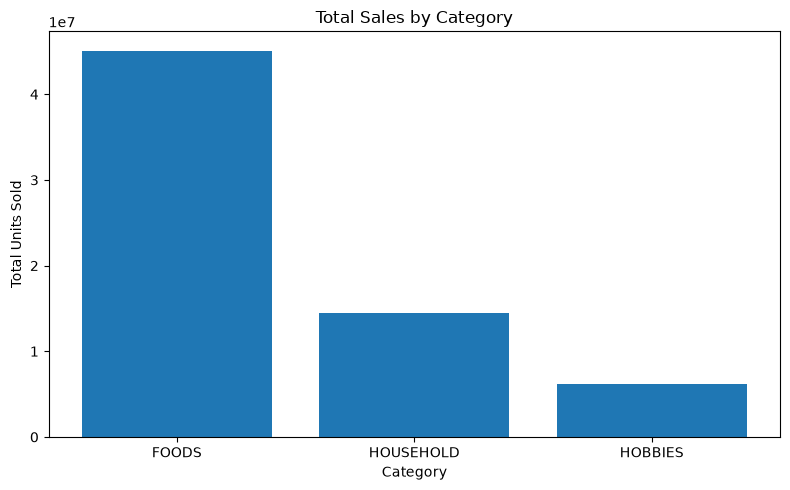

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_sales.index,
    category_sales.values
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

## 4. Store Analysis

Compare total demand across stores to identify store-level differences in sales volume.

In [18]:
store_sales = (
    sales.groupby("store_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
)

print(store_sales)

store_id
CA_3    11188180
CA_1     7698216
TX_2     7214384
WI_2     6544012
WI_3     6427782
TX_3     6089330
CA_2     5685475
TX_1     5595292
WI_1     5149062
CA_4     4103676
dtype: int64


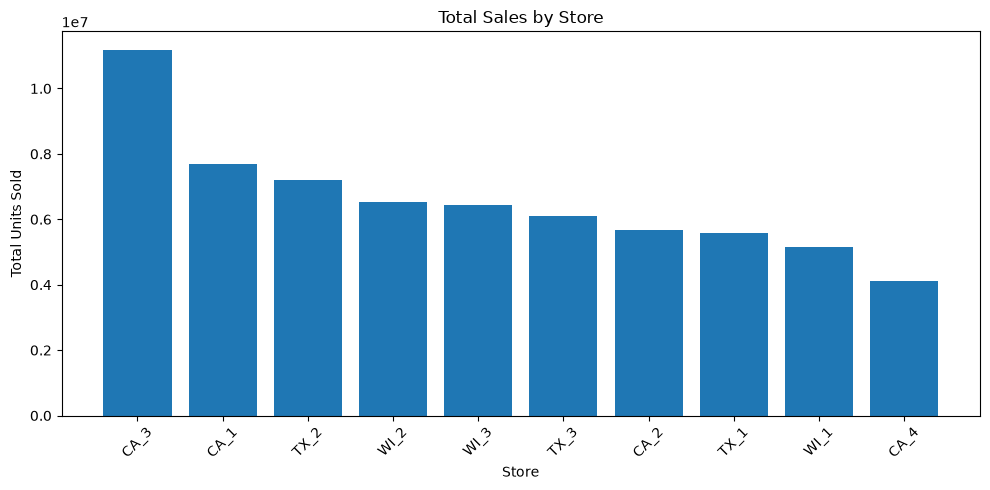

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    store_sales.index,
    store_sales.values
)

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 5. Weekly Seasonality

Analyze demand by day of the week to identify recurring weekly patterns that may improve forecasting performance.

In [20]:
daily_df["day_of_week"] = daily_df["date"].dt.day_name()

weekly_pattern = (
    daily_df
    .groupby("day_of_week")["sales"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

print(weekly_pattern)

day_of_week
Monday       32852.967033
Tuesday      30368.780220
Wednesday    30010.021978
Thursday     30205.007326
Friday       34225.985348
Saturday     41546.894161
Sunday       41130.021898
Name: sales, dtype: float64


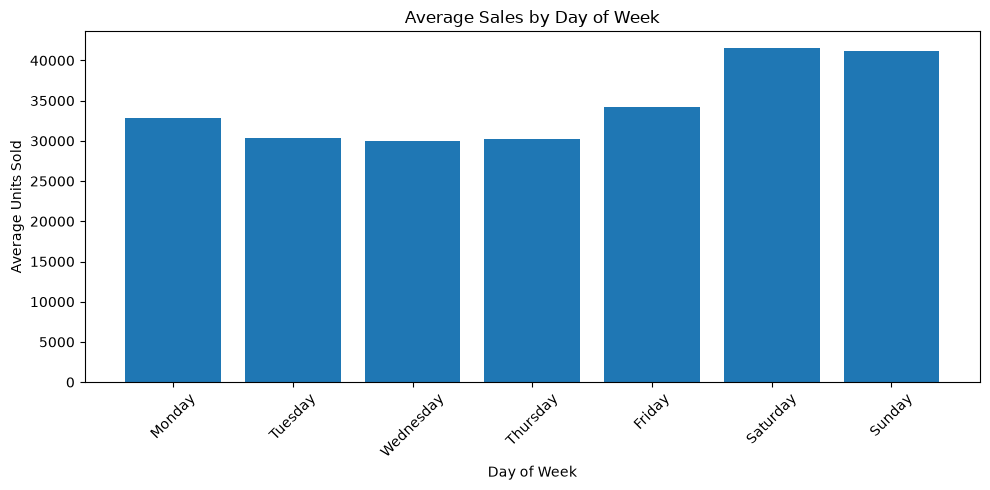

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekly_pattern.index,
    weekly_pattern.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 6. Monthly Seasonality

Analyze demand across months to identify broader annual seasonal patterns.

In [22]:
daily_df["year"] = daily_df["date"].dt.year
daily_df["month"] = daily_df["date"].dt.month

In [23]:
monthly_pattern = (
    daily_df
    .groupby("month")["sales"]
    .mean()
)

print(monthly_pattern)

month
1     33832.348101
2     34644.641176
3     34339.838710
4     34258.683908
5     32503.851613
6     35001.413333
7     35122.419355
8     35946.645161
9     35479.260000
10    34713.477419
11    33290.826667
12    32980.464516
Name: sales, dtype: float64


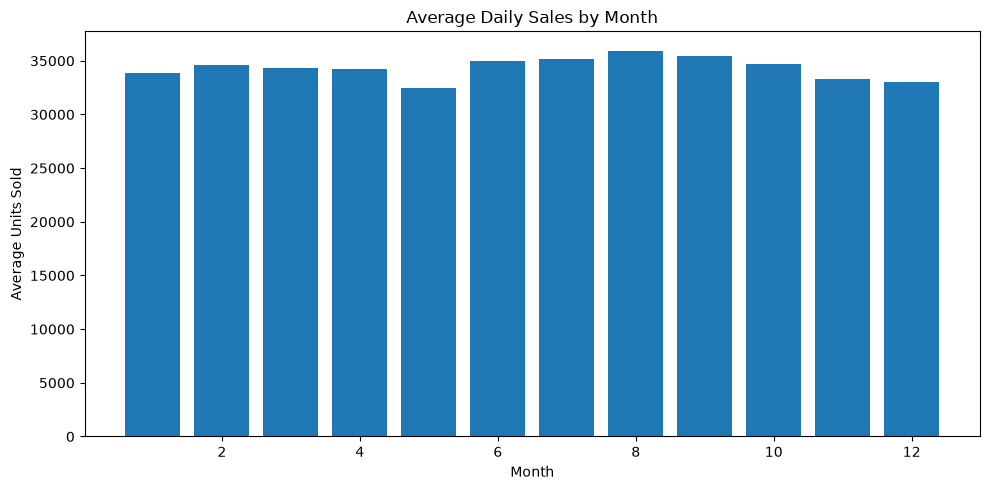

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.tight_layout()
plt.show()

## 7. Event Analysis

Analyze holidays and other events to determine whether they are associated with changes in retail demand and whether their effects vary by event type.

In [25]:
print(
    calendar[
        calendar["event_name_1"].notna()
    ][[
        "date",
        "event_name_1",
        "event_type_1"
    ]].head(20)
)

print("\nEvent counts:")
print(calendar["event_type_1"].value_counts())

          date     event_name_1 event_type_1
8   2011-02-06        SuperBowl     Sporting
16  2011-02-14    ValentinesDay     Cultural
23  2011-02-21    PresidentsDay     National
39  2011-03-09        LentStart    Religious
46  2011-03-16        LentWeek2    Religious
47  2011-03-17    StPatricksDay     Cultural
50  2011-03-20        Purim End    Religious
85  2011-04-24   OrthodoxEaster    Religious
87  2011-04-26       Pesach End    Religious
96  2011-05-05    Cinco De Mayo     Cultural
99  2011-05-08     Mother's day     Cultural
121 2011-05-30      MemorialDay     National
122 2011-05-31   NBAFinalsStart     Sporting
134 2011-06-12     NBAFinalsEnd     Sporting
141 2011-06-19     Father's day     Cultural
156 2011-07-04  IndependenceDay     National
184 2011-08-01   Ramadan starts    Religious
214 2011-08-31      Eid al-Fitr    Religious
219 2011-09-05         LaborDay     National
254 2011-10-10      ColumbusDay     National

Event counts:
event_type_1
Religious    55
National   

In [ ]:
event_calendar = calendar[[
    "date",
    "event_name_1",
    "event_type_1"
]].copy()

daily_events = daily_df.merge(
    event_calendar,
    on="date",
    how="left"
)

daily_events["is_event"] = (
    daily_events["event_name_1"].notna()
)

In [27]:
event_comparison = (
    daily_events
    .groupby("is_event")["sales"]
    .agg([
        "mean",
        "median",
        "count"
    ])
)

print(event_comparison)

                  mean   median  count
is_event                              
False     34489.207504  33714.0   1759
True      32655.149351  33779.5    154


In [28]:
event_type_sales = (
    daily_events[
        daily_events["event_type_1"].notna()
    ]
    .groupby("event_type_1")["sales"]
    .agg([
        "mean",
        "median",
        "count"
    ])
    .sort_values("mean", ascending=False)
)

print(event_type_sales)

                      mean   median  count
event_type_1                              
Sporting      35796.062500  34998.0     16
Cultural      34234.742857  35089.0     35
Religious     33760.692308  33760.0     52
National      29458.509804  32656.0     51


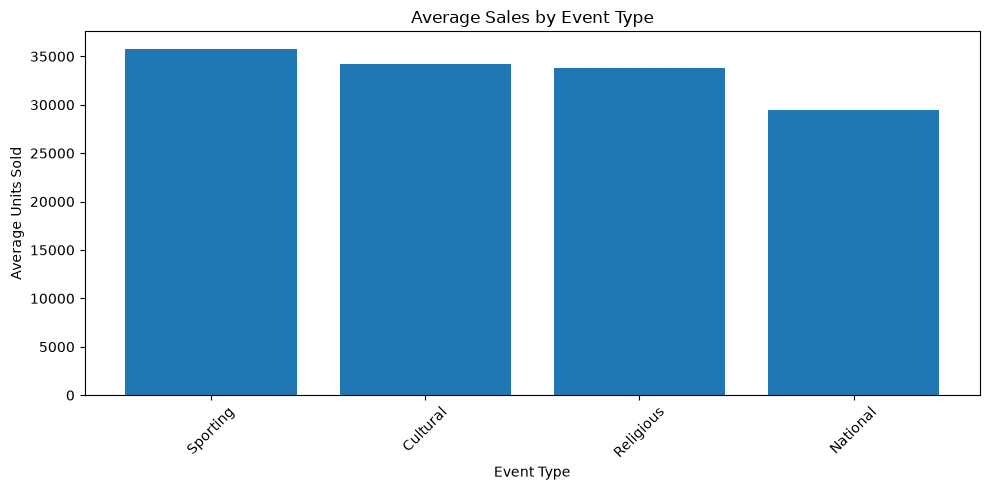

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    event_type_sales.index,
    event_type_sales["mean"]
)

plt.title("Average Sales by Event Type")
plt.xlabel("Event Type")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [30]:
event_sales = (
    daily_events[
        daily_events["event_name_1"].notna()
    ]
    .groupby("event_name_1")["sales"]
    .agg([
        "mean",
        "median",
        "count"
    ])
    .sort_values("mean", ascending=False)
)

print(event_sales.head(15))

                         mean   median  count
event_name_1                                 
LaborDay         42154.600000  44525.0      5
SuperBowl        40924.000000  40971.5      6
Easter           39517.600000  38934.0      5
OrthodoxEaster   38277.000000  40955.0      4
Father's day     36562.000000  39364.5      4
Purim End        35957.000000  33411.0      6
Eid al-Fitr      35267.600000  34886.0      5
ColumbusDay      35164.800000  33790.0      5
VeteransDay      35118.800000  33338.0      5
Ramadan starts   34779.600000  35402.0      5
EidAlAdha        34504.000000  32967.0      5
PresidentsDay    34446.333333  34597.5      6
Mother's day     34211.400000  37390.0      5
IndependenceDay  33710.800000  36783.0      5
NBAFinalsEnd     33564.200000  31698.0      5


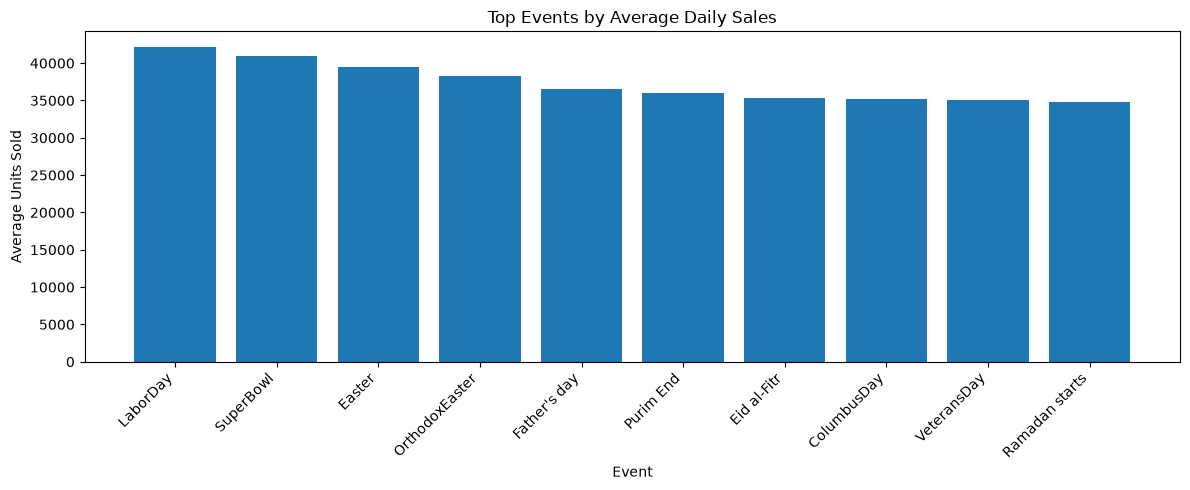

In [31]:
top_events = event_sales.head(10)

plt.figure(figsize=(12, 5))

plt.bar(
    top_events.index,
    top_events["mean"]
)

plt.title("Top Events by Average Daily Sales")
plt.xlabel("Event")
plt.ylabel("Average Units Sold")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## 8. Key EDA Findings

### 1. Strong Weekly Seasonality

Weekend demand is substantially higher than weekday demand, with Saturday and Sunday showing the highest average sales.

**Model implication:** Include day-of-week and lagged demand features.

### 2. Moderate Annual Seasonality

Demand varies throughout the year, with demand generally higher around August–September and lower toward November–December.

**Model implication:** Include month and week-of-year features.

### 3. Significant Store-Level Variation

Sales volume varies substantially across stores.

**Model implication:** Store and state should be included as forecasting features.

### 4. Strong Category Concentration

FOODS represents the largest share of total demand, followed by HOUSEHOLD and HOBBIES.

**Model implication:** Product and category information should be included in the model.

### 5. Event Effects Are Heterogeneous

Events do not universally increase demand. The impact varies by event type and individual event.

**Model implication:** Event type and event name are more informative than a simple event/no-event indicator.

### 6. Pricing May Influence Demand

Prices vary across products, stores, and weeks, providing another potential demand driver.

**Model implication:** Incorporate sell price and price-related features into forecasting.

## 9. Transition to Forecasting

The EDA identified several important sources of demand variation:

- Recent sales history
- Weekly seasonality
- Annual seasonality
- Product characteristics
- Store/location
- Events
- Pricing

These findings motivate the feature engineering strategy used in Notebook 2.

The next notebook will:

1. Create calendar features
2. Create lag features
3. Create rolling demand features
4. Incorporate pricing and event information
5. Establish a seasonal-naive baseline
6. Train a LightGBM forecasting model
7. Evaluate both approaches using MAE, RMSE, and WMAPE
8. Translate forecasting results into inventory-planning insights